# CLL mtscATAC-seq: Fig. 4 and Supplementary Fig. S4

Fig. 4 drawn as one figure, from the outputs of the CLL analysis (`03a_cll.ipynb` → `03b_cll_gene_activity.R` → `03c_cll_gene_activity.ipynb` → `03d_cll_coverage.R`). Run after those four steps.

- Fit: `output/v2/cll/202610/11/080706` (see `03a_cll.ipynb`); LSI clusters from `data/ATAC/PT1_pos.h5ad`.
- Gene activity of the top gene of each clone: `analysis/results/cll/ga_top_gene_of_each_clone.csv` (`03c`).
- Accessibility around PAX9: `analysis/results/cll/r_output/coverage/coverage_fig4d_PAX9_clone4.pdf` (`03d`, drawn by Signac).
- For Supplementary Fig. S4: the high-probability cells of each clone (`analysis/results/cll/r_input/clone_flags.tsv`, `03a`) and the accessibility around HIST1H2AE (`r_output/coverage/coverage_clone4_2_HIST1H2AE.pdf`, `03d`).
- Output: `analysis/results/cll/figure4.pdf` and `supfig4.pdf` (and `.png`).

In [1]:
%cd ../src

.../cloneVI/src


.../site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
import subprocess
import tempfile

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from matplotlib.lines import Line2D

In [3]:
ATAC = '../data/ATAC/PT1_pos.h5ad'
RUN = '../output/v2/cll/202610/11/080706'
OUT = '../analysis/results/cll'
COVERAGE = f'{OUT}/r_output/coverage/coverage_fig4d_PAX9_clone4.pdf'
COVERAGE_S4 = f'{OUT}/r_output/coverage/coverage_clone4_2_HIST1H2AE.pdf'   # Supplementary Fig. S4d (03d)

### Figure style

Each figure of the paper is one matplotlib figure at the text width of the manuscript (505.7 pt), printed without scaling, so every text keeps the size set here. The positions of the panels are decided first, from a few sizes shared by all figures (below: the width of a column, the gaps, the title row, the room of a colorbar), and each panel is then drawn into its axes by the standard functions (`sc.pl.embedding`, `sns.heatmap`). A map is as wide as a column less the room of its colorbar, and as high as the UMAP undistorted, so all maps of a figure have the same size. Titles are centred (the default). Every column begins with a narrow letter column, where the panel letter stands on the baseline of the titles, to the left of its panel. The coverage plot is drawn by Signac in R and placed as an image.

In [4]:
plt.rcParams.update({'font.size': 6.5, 'axes.titlesize': 7, 'axes.labelsize': 6.5, 'xtick.labelsize': 6,
                     'ytick.labelsize': 6, 'legend.fontsize': 6, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'savefig.dpi': 600})
PI_CMAP = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)
VAF_CMAP = sns.cubehelix_palette(as_cmap=True)
EXPR_CMAP = 'viridis'

# sizes shared by all figures (points)
W = 505.69                          # text width
M = 1                               # outer margin, so that frames at the edge are drawn whole
MB = 4                              # bottom margin below a map: half of its lowest colorbar label hangs below it
LG = 9                              # letter column at the left of every column (the gap between columns)
CL = 3                              # clearance at the right of a panel that has no colorbar beside it
GY = 6                              # gap between rows
T = 11                              # title row above a panel; titles and letters stand on its baseline
PAD = 3                             # baseline of the titles above the axes
CB_W, CB_PAD, CB_ROOM = 4, 3, 26    # colorbar beside a map: width, distance, and the room it takes with its labels
SW = (W - 2 * M) / 4                # width of a column (4 columns), letter column included
MW = SW - LG - CB_ROOM              # width of a map
plt.rcParams['axes.titlepad'] = PAD

## 1. The data

In [5]:
den = lambda M: M.toarray() if sp.issparse(M) else np.asarray(M)
atac = sc.read_h5ad(ATAC, backed='r')
fit = sc.read_h5ad(f'{RUN}/cloneVI_result.h5ad')
assert (atac.obs['barcode'].to_numpy() == fit.obs['barcode'].to_numpy()).all()
pi = np.asarray(fit.obsm['pi_deleted'], dtype=float)
phi = np.asarray(fit.varm['phi_deleted'], dtype=float)
variants = [str(v) for v in fit.var_names]
vaf = den(fit.layers['VAF']).astype(float)
j5140, j1260 = variants.index('5140'), variants.index('1260')
K5140 = [int(k) for k in np.argsort(-phi[j5140])[:2]]   # the two clones of 5140 (as in 03a)
K1260 = int(phi[j1260].argmax())                        # the clone of 1260
ga = pd.read_csv(f'{OUT}/ga_top_gene_of_each_clone.csv', index_col=0)
assert (ga.index.to_numpy() == fit.obs['barcode'].to_numpy()).all()
print('clones of 5140:', K5140, ' clone of 1260:', K1260)

clones of 5140: [1, 3]  clone of 1260: 4


In [6]:
# one table of cells for the maps: the CloneVI UMAP and the values drawn
cells = sc.AnnData(obs=pd.DataFrame(index=fit.obs['barcode'].to_numpy()))
cells.obsm['X_umap'] = np.asarray(fit.obsm['X_cloneVI_umap'])
cells.obs['LSI clusters'] = pd.Categorical(atac.obs['lsi_clusters'].astype(int).to_numpy())
for k in (*K5140, K1260):
    cells.obs[f'Clone {k} probability'] = pi[:, k]
cells.obs['5140 VAF'] = vaf[:, j5140]
cells.obs['5140 VAF below 0.9'] = np.where(vaf[:, j5140] > 0.9, 0, vaf[:, j5140])
cells.obs['1260 VAF'] = vaf[:, j1260]
cells.obs['PAX9 gene activity'] = ga['PAX9'].to_numpy()
phi_table = pd.DataFrame(phi, index=variants)

## 2. Fig. 4

a, the LSI clusters on the CloneVI UMAP. b, the clonal probability of the two clones of 5140 and the clone of 1260 (top), and the VAF of their variants (bottom; middle, 5140 VAF with values above 0.9 set to 0). c, the clone-specific allele frequencies $\phi$. d, accessibility around PAX9 in cells with low and high probability of the clone of 1260 (`03d`; without its blank margins, from the top of the row to the bottom of e). e, PAX9 gene activity (colour scale up to the 99th percentile of the cells with activity, as in `03c`).

.../site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
.../site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


figure 505.69 x 252.3 pt; maps 90.9 x 67.4 pt (point size 1.97); c cell 7.2 pt; d 207.2 x 78.4 pt


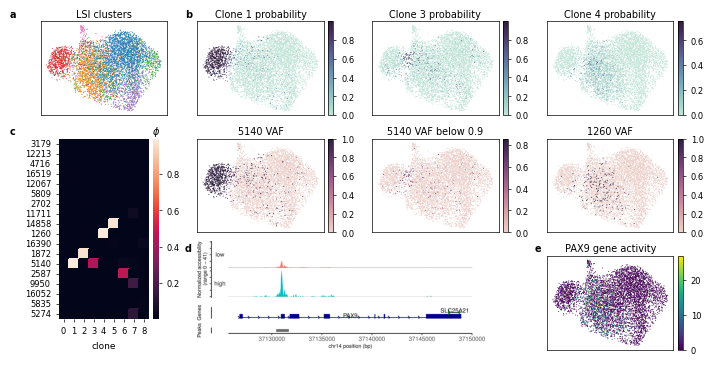

In [7]:
# the positions of the panels (points, from the top left)
u = cells.obsm['X_umap']
MH = MW * np.ptp(u[:, 1]) / np.ptp(u[:, 0])         # height of a map: the UMAP undistorted
SIZE = 1.8 * MW * MH / len(u)                       # point size: the points cover 1.8 times the area of a map
col = lambda j: M + j * SW                          # left of column j (its letter column)
row = [M, M + T + MH + GY, M + 2 * (T + MH + GY)]
with tempfile.TemporaryDirectory() as tmp:          # the Signac plot, as an image without its blank margins
    subprocess.run(['pdftoppm', '-png', '-r', '600', '-singlefile', COVERAGE, f'{tmp}/coverage'], check=True)
    coverage = mpimg.imread(f'{tmp}/coverage.png')
ink = coverage[..., :3].min(axis=2) < 0.99
r, c = np.where(ink.any(axis=1))[0], np.where(ink.any(axis=0))[0]
coverage = coverage[r[0]:r[-1] + 1, c[0]:c[-1] + 1]
DH = T + MH                                          # d has no title: from the top of the row to the bottom of e
DW = DH * coverage.shape[1] / coverage.shape[0]
assert DW <= 2 * SW - LG - CL, DW
H = row[2] + T + MH + MB
fig = plt.figure(figsize=(W / 72, H / 72))

def axes(x, y, w, h):                               # axes at (x, y) from the top left, in points
    return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])

def letter(j, y, s):                                # panel letter in the letter column of column j, on the title baseline
    fig.text(col(j) / W, 1 - (y + T - PAD) / H, s, fontweight='bold', fontsize=plt.rcParams['axes.titlesize'], va='baseline')

emb = dict(basis='umap', show=False, frameon=True, size=SIZE, colorbar_loc=None)
def umap(x, y, color, **kw):
    ax = axes(x, y + T, MW, MH)
    sc.pl.embedding(cells, color=color, ax=ax, **emb, **kw)
    ax.set_xlabel('')
    ax.set_ylabel('')
    if 'cmap' in kw:
        fig.colorbar(ax.collections[0], cax=axes(x + MW + CB_PAD, y + T, CB_W, MH))
    return ax

# a: no colorbar, so the map is centred in its column; c is centred below it
cx = col(0) + LG + (SW - LG) / 2
letter(0, row[0], 'a')
umap(cx - MW / 2, row[0], 'LSI clusters', legend_loc=None)

# b
letter(1, row[0], 'b')
for j, k in enumerate((*K5140, K1260)):
    umap(col(1 + j) + LG, row[0], f'Clone {k} probability', cmap=PI_CMAP, vmin=0)
for j, c in enumerate(['5140 VAF', '5140 VAF below 0.9', '1260 VAF']):
    umap(col(1 + j) + LG, row[1], c, cmap=VAF_CMAP, vmin=0)

# c: square cells, as large as fit between the variant names (26 pt) and the colorbar (as beside a map), and above
# the clone axis (20 pt); the colorbar is as high as the heatmap, with phi as its title
letter(0, row[1], 'c')
L, B = 26, 20
y0 = row[1] + T
n_var, n_clone = phi_table.shape
cell = min(2 * min(cx - col(0) - LG - L, col(1) - CB_ROOM - cx) / n_clone, (H - M - y0 - B) / n_var)
hw, hh = n_clone * cell, n_var * cell
ax = axes(cx - hw / 2, y0, hw, hh)
cax = axes(cx + hw / 2 + CB_PAD, y0, CB_W, hh)
sns.heatmap(phi_table, ax=ax, square=True, linewidths=0.3, linecolor='face', yticklabels=True, cbar_ax=cax)
cax.set_title(r'$\phi$')
ax.set_xlabel('clone')

# d, e
letter(1, row[2], 'd')
ax = axes(col(1) + LG, row[2], DW, DH)
ax.imshow(coverage, aspect='auto')
ax.axis('off')
letter(3, row[2], 'e')
v = cells.obs['PAX9 gene activity'].to_numpy()
umap(col(3) + LG, row[2], 'PAX9 gene activity', cmap=EXPR_CMAP, vmin=0, vmax=np.quantile(v[v > 0], 0.99))

fig.savefig(f'{OUT}/figure4.pdf')
fig.savefig(f'{OUT}/figure4.png', dpi=300)
print(f'figure {W} x {H:.1f} pt; maps {MW:.1f} x {MH:.1f} pt (point size {SIZE:.2f}); c cell {cell:.1f} pt; d {DW:.1f} x {DH:.1f} pt')

## 3. Supplementary Fig. S4

a, the clonal probabilities of the nine kept clones; b, their high-probability cells (the cells with the largest $\pi$ that together account for 50% of the probability of the clone, `03a`); c, the $\pi$-weighted mean VAF and $\phi$ for each variant and clone; d, the accessibility around HIST1H2AE, the gene of rank 2 of Clone 4 (`03d`; without its blank margins). Each panel in its own rows; the maps are on five columns (nine maps in each of a and b; on four columns the figure would not fit on a page), with the other sizes shared by all figures.

.../site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
.../site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
.../site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
.../site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Par

figure 505.69 x 457.8 pt; maps 65.7 x 48.7 pt (point size 1.03); c cells 8.8 pt; d 239.8 x 120.7 pt


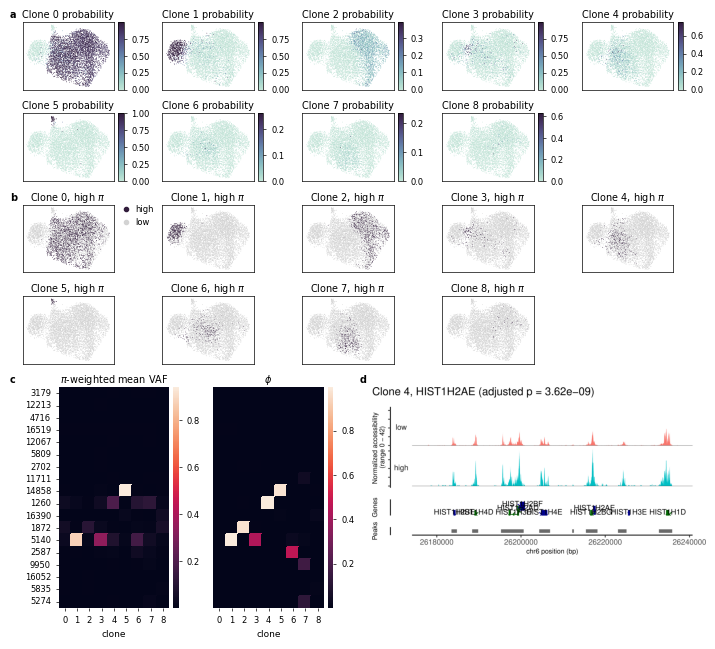

In [8]:
flags = pd.read_csv(f'{OUT}/r_input/clone_flags.tsv', sep='\t', index_col=0)   # the high-probability cells of each clone (03a)
nk = pi.shape[1]
assert flags.shape == (len(cells), nk)
HIGH_COL = {'low': '#d3d3d3', 'high': PI_CMAP(1.0)}                                # as in 03a
for k in range(nk):
    cells.obs[f'Clone {k} probability'] = pi[:, k]
    cells.obs[f'Clone {k}, high $\\pi$'] = pd.Categorical(np.where(flags[f'clone_{k + 1}'] == 1, 'high', 'low'), categories=['low', 'high'])
vaf_pi = (vaf.T @ pi) / pi.sum(0)                                                    # pi-weighted mean VAF (03a)
with tempfile.TemporaryDirectory() as tmp:                                           # the Signac plot, without its blank margins
    subprocess.run(['pdftoppm', '-png', '-r', '600', '-singlefile', COVERAGE_S4, f'{tmp}/coverage'], check=True)
    cov = mpimg.imread(f'{tmp}/coverage.png')
ink = cov[..., :3].min(axis=2) < 0.99
r_, c_ = np.where(ink.any(axis=1))[0], np.where(ink.any(axis=0))[0]
cov = cov[r_[0]:r_[-1] + 1, c_[0]:c_[-1] + 1]

u = cells.obsm['X_umap']
# five columns in this figure (nine maps in each of a and b; with four columns S4 would not fit on a page): a and b in
# two rows each (five and four maps), c and d side by side in the last row
NC = 5
SW5 = (W - 2 * M) / NC
MW5 = SW5 - LG - CB_ROOM
MH5 = MW5 * np.ptp(u[:, 1]) / np.ptp(u[:, 0])
SIZE = 1.8 * MW5 * MH5 / len(u)
col = lambda j: M + j * SW5
RH = T + MH5 + GY
LV, BC = 26, 20                                       # variant names; below c (clone numbers, 'clone')
G2 = 6                                                # gap between the two heatmaps
HALF = (W - 2 * M) / 2
ccell = (HALF - LG - LV - CB_ROOM - G2 - CB_ROOM) / (2 * nk)   # cells of c, as wide as half the text width allows
nv = len(variants)
DW = HALF - LG - CL
DH = DW * cov.shape[0] / cov.shape[1]
na = -(-nk // NC)
y_b, y_cd = M + na * RH, M + 2 * na * RH
H = y_cd + max(T + nv * ccell + BC, T + DH) + MB
fig = plt.figure(figsize=(W / 72, H / 72))
axes = lambda x, y, w, h: fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])
letter = lambda x, y, s: fig.text(x / W, 1 - (y + T - PAD) / H, s, fontweight='bold', fontsize=plt.rcParams['axes.titlesize'],
                                  va='baseline')
emb = dict(basis='umap', show=False, frameon=True, size=SIZE, colorbar_loc=None)
def umap(x, y, color, **kw):
    ax = axes(x, y + T, MW5, MH5)
    sc.pl.embedding(cells, color=color, ax=ax, **emb, **kw)
    ax.set_xlabel(''); ax.set_ylabel('')
    if 'cmap' in kw:
        fig.colorbar(ax.collections[0], cax=axes(x + MW5 + CB_PAD, y + T, CB_W, MH5))
    return ax

letter(col(0), M, 'a')
for k in range(nk):
    umap(col(k % NC) + LG, M + (k // NC) * RH, f'Clone {k} probability', cmap=PI_CMAP, vmin=0)
letter(col(0), y_b, 'b')
for k in range(nk):
    x, y = col(k % NC) + LG, y_b + (k // NC) * RH
    umap(x, y, f'Clone {k}, high $\\pi$', palette=list(HIGH_COL.values()), legend_loc=None)
    if k == 0:
        fig.legend(handles=[Line2D([], [], marker='o', ls='', markersize=3, color=HIGH_COL[g], label=g) for g in ('high', 'low')],
                   loc='upper left', bbox_to_anchor=((x + MW5 + CB_PAD) / W, 1 - (y + T) / H), frameon=False,
                   handletextpad=0.1, borderaxespad=0, borderpad=0)

# c, in the left half of the last row
letter(M, y_cd, 'c')
x = M + LG + LV
for i, (val, ttl) in enumerate([(vaf_pi, r'$\pi$-weighted mean VAF'), (phi, r'$\phi$')]):
    ax = axes(x, y_cd + T, nk * ccell, nv * ccell)
    sns.heatmap(pd.DataFrame(val, index=variants), ax=ax, square=True, linewidths=0.3, linecolor='face',
                yticklabels=(i == 0), cbar_ax=axes(x + nk * ccell + CB_PAD, y_cd + T, CB_W, nv * ccell))
    ax.set_title(ttl)
    ax.set_xlabel('clone')
    x += nk * ccell + CB_ROOM + G2

# d, in the right half
letter(M + HALF, y_cd, 'd')
ax = axes(M + HALF + LG, y_cd + T, DW, DH)
ax.imshow(cov, aspect='auto')
ax.axis('off')

fig.savefig(f'{OUT}/supfig4.pdf')
fig.savefig(f'{OUT}/supfig4.png', dpi=300)
print(f'figure {W} x {H:.1f} pt; maps {MW5:.1f} x {MH5:.1f} pt (point size {SIZE:.2f}); c cells {ccell:.1f} pt; d {DW:.1f} x {DH:.1f} pt')